# From produced water to lithium carbonate: the sodium-saponified HBTA/TOPO process

**The question.** Oilfield produced water carries lithium at tens to a few hundred milligrams per litre, alongside much
more sodium, calcium and magnesium. What would a continuous solvent-extraction process cost to run on measured produced
waters, and at what lithium carbonate price would it cover that cost?

**Process boundary and conditions.** Raw produced water in, lithium carbonate (Li$_2$CO$_3$) out, for four measured
waters: three Smackover samples from Arkansas (MS-2, BR-2 and Mars Hill) and one Marcellus sample from Pennsylvania
(Westmoreland). Two extraction routes are compared:

- **saponified HBTA/TOPO** needs the whole water softened first (sodium hydroxide and soda ash precipitate the calcium
  and magnesium), then extraction, scrub, strip, organic reuse and carbonation;
- **D2EHDTPA/BuPhen** extracts from the raw water without whole-water softening, with ideal cleanup of the strip liquor
  assumed.

The operating cost counts reagents, sludge disposal, and extractant and diluent replacement, at base and optimistic
prices; energy, capital and labor are excluded. D2EHDTPA/BuPhen's two extractants are not priced; instead the paper
finds the highest BuPhen price the process could pay. The break-even price is the lithium carbonate price at which the
product pays the operating cost, in USD per kg of lithium carbonate equivalent (LCE; 1 kg of lithium makes 5.32 kg of
Li$_2$CO$_3$).

**The paper's results**, read from the result tables the manuscript uses. HBTA/TOPO uses the primary calibration;
both carbonate-recovery columns show base-case recovery. D2EHDTPA/BuPhen uses Figiel ion parameters.

In [1]:
import lithium_tutorial_tools as tools
import lithium_produced_water_tools as pw

pw.paper_headline()

Assumed lithium carbonate price: 17.5 (base) to 20.9 (optimistic) USD/kg LCE


water                     \
             Li (mg/L) (Ca+Mg)/Li (kg/kg)   
MS-2               168                239   
BR-2               252                171   
Mars Hill          423               74.6   
Westmoreland       117               27.3   

             saponified HBTA/TOPO, softened water  \
                                 Li to Li2CO3 (%)   
MS-2                                         69.2   
BR-2                                         66.4   
Mars Hill                                    64.4   
Westmoreland                                 73.8   

                                                   \
             break-even, base prices (USD/kg LCE)   
MS-2                                          356   
BR-2                                          246   
Mars Hill                                     138   
Westmoreland                                1,047   

                                                         \
             break-even, optimistic prices (USD/kg LCE)   
MS-2                                               92.7   
BR-2                                               66.2   
Mars Hill                                          32.9   
Westmoreland                                        127   

             D2EHDTPA/BuPhen, raw water  
                       Li to Li2CO3 (%)  
MS-2                               78.1  
BR-2                               78.3  
Mars Hill                          78.4  
Westmoreland                       78.5

**What the results mean.**

- **Recovering the lithium is not the hard part; paying for it is.** Both routes bring most of the raw-water lithium to
  lithium carbonate, but with HBTA/TOPO the break-even price is far above the assumed lithium carbonate price at every
  water, even at optimistic prices. Softening the whole water and replacing lost HBTA cost more than the lithium is
  worth.
- **Lithium-rich water costs least per kilogram.** Mars Hill, with the most lithium, has the lowest HBTA/TOPO
  break-even price and Westmoreland, with the least, the highest, even though Westmoreland carries the least calcium
  and magnesium per kilogram of lithium.
- **D2EHDTPA/BuPhen is the open candidate.** It needs no whole-water softening; whether it pays depends on the BuPhen
  price and on the strip-liquor cleanup being as ideal as assumed (the paper's other results, near the end).

**Claim boundary.** These are model predictions: ePC-SAFT equilibrium stages with constants fitted to laboratory data on
other solutions, laboratory scrub and strip fractions transferred to produced water, and screening prices. Nothing was
measured on these waters. The notebook below solves the HBTA/TOPO process for MS-2 and Mars Hill at base prices and
ends by checking them against the paper's results; the other entries are read from the paper's result tables.

## Running this notebook

The rest of the notebook builds and solves the HBTA/TOPO process for MS-2 one step per cell, like stepping through a
process simulator, with the IDAES and PrOMMiS process-modeling tools: softening, countercurrent extraction closed by
ePC-SAFT equilibrium, scrub, strip, acid recovery, neutralization, organic reuse, carbonation and operating cost. It then
solves Mars Hill, compares the two waters, shows how the unit models are connected, lets you explore the options of the
process explorer app with widgets, summarizes the paper's results it does not solve, and ends by checking every
reproduced number against the paper's results.

**Runtime:** about 2 minutes. **How to run:** set up the environment once as described on the setup page beside this
notebook, then open the notebook in JupyterLab and choose *Run All*, or run the cells in order, top to bottom. The
setup page also shows how to run it without opening it, and how to serve it as an app.

The helper functions called below are in the tutorial helper modules imported above. Each takes the model `m` and does
one job that would otherwise bury the flowsheet steps: writing constraints, starting points, figures and checks. The
software this run uses:

In [2]:
tools.versions()

,version
ePC-SAFT Engine,1.2.0
IDAES,2.13.0
PrOMMiS,1.1.0
Pyomo,6.10.1


## Background

Oilfield produced water is the salty water that comes up with oil and gas. Some of it carries lithium at tens to a
few hundred milligrams per litre, alongside much more sodium, calcium and magnesium.

![Block flow diagram of the process](lithium_produced_water_process_block_flow_diagram.png)

*Block flow diagram from the manuscript (Figure 1). This notebook follows the upper lane, sodium-saponified HBTA/TOPO with
whole-water softening.*

The process has five steps:

1. **Softening.** Sodium hydroxide and soda ash precipitate magnesium and calcium as sludge; hydrochloric acid then
   brings the water to an assumed process pH of 5.77.
2. **Extraction.** The softened water flows against an organic liquid through countercurrent mixer-settler stages.
   The organic holds HBTA with TOPO in a kerosene-like diluent, with 70 % of the HBTA in its sodium (saponified) form,
   so it trades sodium rather than acid for lithium.
3. **Scrub.** A dilute hydrochloric acid wash removes most of the sodium the organic picked up, losing some lithium.
4. **Strip.** Stronger hydrochloric acid moves the lithium into a small volume of water, the strip liquor. Most unused
   acid is recovered and the rest neutralized. The organic is re-saponified and reused; a small part is lost and
   replaced each pass.
5. **Carbonation.** Soda ash precipitates lithium carbonate (Li$_2$CO$_3$), the product, from the concentrated strip
   liquor. Most of the mother liquor is recycled; a purge removes salt.

**The case solved here.** 1 m$^3$/h of MS-2 water at base-case prices, with the design the study's optimization selected
for it (5 extraction stages, 0.10 mol/L HBTA with equal TOPO, O/A = 1, 70 % saponified). The design is fixed, so the
flowsheet is solved once as a simulation. The Mars Hill water is then solved at its own selected design. The operating
cost counts reagents, extractant and diluent replacement, and sludge disposal; it excludes energy, capital and labor.

### Glossary

| Term | Meaning |
|---|---|
| HBTA, TOPO | benzoyltrifluoroacetone (the extractant that binds lithium) and trioctylphosphine oxide (its partner in the organic) |
| saponified | extractant pre-reacted with sodium hydroxide, so it exchanges sodium, not acid, for lithium |
| NaOH, Na$_2$CO$_3$, HCl | sodium hydroxide, soda ash, hydrochloric acid (priced as a 31 wt% solution) |
| LCE | lithium carbonate equivalent: 1 kg of lithium makes 5.32 kg of Li$_2$CO$_3$ |
| O/A | organic-to-aqueous flow ratio |
| raffinate | the water leaving the last extraction stage |
| MS-2, BR-2, Mars Hill | USGS Smackover produced-water samples from Arkansas (wells MSPU 4-W1, BSW 12 M and Cornelius 1) |
| Westmoreland | USGS Marcellus produced-water sample from Westmoreland County, Pennsylvania |
| ePC-SAFT, Engine | the thermodynamic model of each extraction stage, and the ePC-SAFT equilibrium library that evaluates it |
| Arc | a connection that equates the outlet port of one unit with the inlet port of the next |

## Step 1: Import the tools

The IDAES and PrOMMiS pieces of the flowsheet and the Lithium_Extraction project's modules that write the downstream
units; the tutorial helpers were imported at the top.

In [3]:
from idaes.core import FlowDirection, FlowsheetBlock
from idaes.core.util.model_statistics import degrees_of_freedom
from prommis.solvent_extraction.solvent_extraction import SolventExtraction
from pyomo.environ import ConcreteModel, value

from prommis.lithium_extraction.process import (
    acid_recovery as chain,
    costing,
    strip_and_carbonation as downstream,
)
from prommis.lithium_extraction.extraction import set_c, stage
from prommis.lithium_extraction.extraction.stage import (
    ExtentReactions,
    MolarFlowParameters,
)

## Step 2: Inputs

### 2.1 The waters and their selected designs

Each water is one measured USGS sample. The calcium and magnesium per kilogram of lithium set most of the softening
cost. The study optimized each water over 1 to 5 extraction stages and 0.1 to 0.4 mol/L HBTA, at O/A = 1 and 70 %
saponification, requiring at least 95 % lithium extraction. The design kept for each water is the cheapest, with ties
within 0.1 % going to fewer stages.

In [4]:
pw.waters()

,Li (mg/L),Na (mg/L),Ca (mg/L),Mg (mg/L),Cl (mg/L),(Ca+Mg)/Li (kg/kg),selected stages,HBTA (mol/L organic),O/A,saponified fraction
MS-2,168,"64,100","36,900","3,310","174,000",239,5,0.1,1,0.7
Mars Hill,423,"72,500","29,300","2,243","176,679",74.6,5,0.112,1,0.7


### 2.2 Softening

Softening precipitates the hardness ions with fixed doses per litre of raw water:

$$
\mathrm{Mg^{2+} + 2\,OH^- \longrightarrow Mg(OH)_{2(s)}},
\qquad n_{NaOH} = 2.4\, n_{Mg}
$$

$$
\mathrm{M^{2+} + CO_3^{2-} \longrightarrow MCO_{3(s)}},\quad \mathrm{M = Ca, Sr, Ba},
\qquad n_{Na_2CO_3} = 1.2\,(n_{Ca} + n_{Sr} + n_{Ba})
$$

then hydrochloric acid brings the water to pH 5.77, an assumption adopted from MS-2 for every water. Each precipitate
is filtered as a cake holding 70 % liquid by mass and washed with one volume of water per volume of cake liquid; the
lithium in the liquid the cake keeps is the softening loss.

The geochemistry library Reaktoro solves each dose. `pw.soften` runs the Lithium_Extraction project's softening
script as a subprocess, as the study did, in the Python the setup page names.

In [5]:
softened = {site: pw.soften(site) for site in pw.WATERS}
pw.softening_table(softened)

,NaOH (kg/m3 raw),soda ash (kg/m3 raw),"HCl, 31% (kg/m3 raw)",wet sludge (kg/m3 raw),softened water (L per L raw),Ca+Mg left (mg/L),Li kept in softened water (%)
MS-2,13.1,120,36.4,342,1.02,0.0627,92.8
Mars Hill,8.86,96.3,28.6,273,1.01,0.069,94.3


## Step 3: The extraction chemistry

Steps 3 to 9 solve the main case, MS-2. Inside the extraction stages, flows are mol/h at 1 L/h of softened water; the
downstream units use 1 L/h of raw water, and $v$ (litres of softened water per litre of raw water) converts between
them.

With HBTA written HA, TOPO written T and M = Li or Na, each stage reaches equilibrium in three reactions:

$$
\mathrm{M^+_{(aq)} + HA_{(org)} + T_{(org)} \;\rightleftharpoons\; MA{\cdot}T_{(org)} + H^+_{(aq)}}
\qquad \text{(R1: M = Li, R2: M = Na)}
$$

$$
\mathrm{HA_{(org)} \;\rightleftharpoons\; H^+_{(aq)} + A^-_{(aq)}} \qquad \text{(R5: HBTA dissolving into the water)}
$$

Subtracting R2 from R1 gives the sodium-for-lithium exchange that the saponified organic performs:
$\mathrm{Li^+_{(aq)} + NaA{\cdot}T_{(org)} \rightleftharpoons LiA{\cdot}T_{(org)} + Na^+_{(aq)}}$. ePC-SAFT supplies the
activities, and each reaction is at equilibrium when $\sum_{p,i}\nu_{r,pi}\ln a_{pi} = \ln K_r$, with the Li/Na
exchange constant from the single-stage fit.

`pw.starting_profile` first solves the stages one at a time with the Engine, sweeping until the organic leaving each
stage stops changing. That profile is the flowsheet's starting point, and it tells which reactions are active in each
stage: water autoprotolysis ($\mathrm{H_2O \rightleftharpoons H^+ + OH^-}$) matters only in some. `pw.stage_chemistries`
compiles one Engine record per stage for its active reactions.

In [6]:
site = "MS2"
water = softened[site][pw.CASE]
v = water["feed_l"]  # L softened water per L raw water
start = pw.starting_profile(site, softened)
chemistries = pw.stage_chemistries(site, start)
print(
    f"{len(chemistries)} stages, {len(set(map(id, chemistries)))} Engine record(s); v = {v:.4f}"
)

5 stages, 1 Engine record(s); v = 1.0152


## Step 4: Build the extraction stages

### 4.1 Model, property packages and transfer extents

As in every IDAES model, a Pyomo `ConcreteModel` holds a steady-state `FlowsheetBlock`. Each phase gets a molar-flow
property package. In each stage $k$ the transfer extents $\boldsymbol\xi_k$ conserve lithium, sodium,
exchangeable hydrogen and total BTA:

$$
\mathbf n^{out}_k = \mathbf n^{in}_k + \mathbf N\,\boldsymbol\xi_k, \qquad \mathbf C\,\mathbf N = \mathbf 0 .
$$

In [7]:
m = ConcreteModel()
m.fs = FlowsheetBlock(dynamic=False)
m.fs.aqueous_properties = MolarFlowParameters(
    phase="aqueous", species=set_c.SUPPORTS[0]
)
m.fs.organic_properties = MolarFlowParameters(
    phase="organic", species=set_c.SUPPORTS[1]
)
m.fs.extents = ExtentReactions(stoichiometry=tools.extent_stoichiometry(chemistries[0]))

### 4.2 The extraction unit

One PrOMMiS `SolventExtraction` unit holds all the stages: water flows forward from stage 1, organic backward from
the last stage. `label_streams` names the feeds `m.fs.boundary[s]` and the stage outlets `m.fs.stage[k].outlet[s]`,
and records $v$.

In [8]:
m.fs.extraction = SolventExtraction(
    number_of_finite_elements=len(chemistries),
    heterogeneous_reaction_package=m.fs.extents,
    aqueous_stream={
        "property_package": m.fs.aqueous_properties,
        "flow_direction": FlowDirection.forward,
    },
    organic_stream={
        "property_package": m.fs.organic_properties,
        "flow_direction": FlowDirection.backward,
    },
)
tools.label_streams(m, v)

### 4.3 Equilibrium in every stage

The Engine closes each stage, one equation per independent species:

$$
n^{out}_{s,k} = \mathcal E_s\!\left(\mathbf n^{in}_k;\ T, P\right).
$$

Two more conditions keep the Engine record consistent: the TOPO it counts follows the extractant,
$n_{T,total} = \mathrm{O/A}\cdot c$, and no stage may leave negative free HBTA or TOPO.

In [9]:
tools.add_stage_equilibrium(m, chemistries)
pw.add_extractant_inventory(m, site)

### 4.4 Feeds

The softened water and the fresh organic entering the stages, per litre of softened water. The organic is 0.10 mol/L
HBTA with equal TOPO in diluent, with 70 % of the HBTA in its sodium form.

In [10]:
pw.feed_extraction(m, site, water)

,softened water,fresh organic
mmol per L of softened water,,
water,"55,508",0
lithium-cation,22.1,0
sodium-cation,"4,931",0
hydrogen-cation,0.00169,0
hydroxide-anion,0,0
bta-anion,0,0
chloride-anion,"4,954",0
hbta,0,30
topo,0,30


### 4.5 The design and the degrees of freedom

`pw.add_design` adds the three design variables, O/A, the HBTA concentration $c$ and the saponified fraction
$r_{Na}$, as fixed variables, and writes the fresh-organic feed in terms of them (per litre of softened water):

$$
n_{HA,in} = n_{T,in} = \mathrm{O/A}\cdot c\,(1 - r_{Na}), \qquad
n_{NaA{\cdot}T,in} = \mathrm{O/A}\cdot c\, r_{Na}.
$$

In the paper's optimization only the HBTA concentration $c$ was free, chosen at each stage count to minimize the
operating cost; O/A = 1 and 70 % saponification were fixed. Here all three stay fixed at the selected design, so the solve
is a simulation and the model must be square.

In [11]:
fixed = pw.add_design(m, site, water)
assert degrees_of_freedom(m) == 0
fixed

,value
organic_to_aqueous_ratio,1
extractant_mol_l,0.1
saponification_ratio,0.7


## Step 5: Initialize and solve the extraction stages

As in the IDAES tutorials, one part is solved before the connected flowsheet. `stage.initialize` loads the starting
profile into every stage and sets the extents from the balances. IPOPT then solves the stages together (exact second
derivatives, tight tolerances, optimality conditions checked from the log), and `pw.check_extraction` solves every
stage again on its own with the Engine: the flowsheet outlets must agree within $10^{-9}$ mol/L, and each stage must
keep the reactions its Engine record was compiled for. The table lists the streams entering and leaving the
stages, as the unit model's `report()` does, in mol per litre of softened water.

In [12]:
stage.initialize(m, pw.stage_amounts(start))
pw.solve(m, "MS2_extraction")["kkt"]

{'stationarity': 0.0,
 'complementarity': 0.0,
 'feasibility': 1.4210854715202004e-14,
 'multiplier_sign': 0.0}

In [13]:
extraction = pw.check_extraction(m)
print(
    f"Lithium extraction: {100 * value(m.fs.design.li_extraction):.2f} % of the softened water's lithium"
)
tools.stream_table(m.fs.extraction, "softened water")

Lithium extraction: 99.56 % of the softened water's lithium


,aqueous Inlet,aqueous Outlet,organic Inlet,organic Outlet
mol per L of softened water,,,,
water,55.5,55.5,,
lithium-cation,0.0221,9.82e-05,,
sodium-cation,4.93,4.96,,
hydrogen-cation,1.69e-06,4.18e-10,,
chloride-anion,4.95,4.95,,
hydroxide-anion,0,1.78e-05,,
bta-anion,0,0.00364,,
diluent,,,4.33,4.33
hbta,,,0.03,0.03


## Step 6: Choose the downstream alternative

Two choices are discrete: whether the scrub acid is set by its source ratio or by the stoichiometric demand of the
metals it removes, and which interval of the measured lithium carbonate solubility table the carbonation salt level
falls in. Every combination is checked before the solve (enough strip acid, a salt level inside the measured data);
the first admissible one is used; the summary counts the combinations and names the one selected. `pw.downstream_accounts` then computes the closed-form material balance and prices
of the downstream steps, used to start the units and to price them.

In [14]:
candidate, alternatives = pw.downstream_alternatives(m, site, softened)
assumptions, accounts = pw.downstream_accounts(m, site, candidate)
alternatives

combinations checked                                      16
admissible combinations                                    1
selected: scrub acid set by                     source ratio
selected: carbonation NaCl interval (mol/kg)        2 to 2.5
Name: downstream alternative, dtype: object

## Step 7: Add the downstream units

### 7.1 Scrub and strip

Two single-stage PrOMMiS `SolventExtraction` units. Their transfer is a measured fraction of the metal held by the
entering organic, not an equilibrium calculation. In each, a complex gives its metal to the acid and frees its HBTA
and TOPO:

$$
\mathrm{MA{\cdot}T_{(org)} + H^+_{(aq)} \longrightarrow M^+_{(aq)} + HA_{(org)} + T_{(org)}},
\qquad n_{M,aq}^{out} = f_M\, n_{M,org}^{in}
$$

- scrub: 1 mol/L HCl at one tenth of the organic flow; $f_{Na} = 0.90$, $f_{Li} = 0.10$ (base case);
- strip: 2.5 mol/L HCl at one tenth of the organic flow; $f_{Li} = 0.95$ (Zhang et al. 2017, Fig. 6), $f_{Na} = 1$.

The scrub takes the loaded organic leaving stage 1 (scaled by $v$ to raw water), and an Arc carries the scrubbed
organic to the strip.

In [15]:
pw.add_scrub_and_strip(m, assumptions, candidate, accounts)

### 7.2 Acid recovery, neutralization and concentration

A `Separator` returns 90 % of the unused strip acid. A `Translator` moves the liquor into a WaterTAP aqueous
package, a `Mixer` adds one NaOH per remaining H⁺ ($\mathrm{H^+ + OH^- \to H_2O}$), and a `Separator` concentrates
the liquor to 1 mol Li per kg of water, returning the removed water to the strip. The strip-water volume is one tenth
of the organic, $\mathrm{O/A}\cdot v/10$ litres per litre of raw water.

In [16]:
downstream.liquor_properties(m.fs)
concentrate = chain.aqueous(
    m.fs, assumptions, m.fs.design.organic_to_aqueous_ratio * v, m.fs.strip.metals["Li"]
)

### 7.3 Organic reuse

Translators and separators count the stripped organic, send the lithium still on it out, lose 1 % of the organic
per pass, and add fresh HBTA, TOPO and diluent for the loss and for the HBTA dissolved into the raffinate. A
single-stage `SolventExtraction` re-saponifies 70 % of the HBTA:
$\mathrm{HA_{(org)} + T_{(org)} + Na^+_{(aq)} + OH^-_{(aq)} \to NaA{\cdot}T_{(org)} + H_2O}$. The prepared organic is
checked against the extraction's organic feed after the solve; there is no recycle Arc into the extraction.

In [17]:
chain.organic(m.fs, m, assumptions, v, "hbta")

### 7.4 Carbonation

A `Mixer` joins the concentrate, soda ash and recycled mother liquor; the PrOMMiS `Precipitator` forms the product at
70 °C; a `Separator` recycles 90 % of the mother liquor and purges 10 %:

$$
\mathrm{2\,Li^+ + CO_3^{2-} \longrightarrow Li_2CO_{3(s)}}, \qquad
n_{Li,mother} = 2\, s(m_{NaCl})\, W, \qquad
s(m_{NaCl}) = s_0 + (s_1 - s_0)\,\frac{m_{NaCl} - m_0}{m_1 - m_0} ,
$$

where $W$ is the mother-liquor water (kg) and $s$ the Li$_2$CO$_3$ solubility, interpolated in Ge et al. (2025)
Table 4 inside the measured NaCl interval $[m_0, m_1]$ chosen in Step 6; soda ash leaves 0.5 mol/kg excess carbonate.
This call also expands every Arc into equality constraints (`network.expand_arcs`).

In [18]:
downstream.connect(m.fs, concentrate, assumptions, candidate, accounts)

### 7.5 Initialize the downstream units

The units downstream of extraction are solved in sequence, block by block (Pyomo's
`solve_strongly_connected_components`), with the extraction held at its solution; the carbonation recycle loop
starts from its closed-form balance.

In [19]:
pw.initialize_downstream(m, assumptions, accounts)

### 7.6 Costing

An IDAES `FlowsheetCostingBlock` registers one flow per priced item. At 1 m$^3$/h of raw water,

$$
C_{op} = \sum_j p_j\, \dot m_j \ \ [\mathrm{USD/m^3}], \qquad
C_{Li} = \frac{C_{op}}{\dot m_{Li}} \ \ [\mathrm{USD/kg\ Li}], \qquad
P_{LCE}^{\,\text{break-even}} = \frac{C_{Li}}{5.32} .
$$

`pw.priced_flows` lists each item's mass flow (from the units above, or fixed softening amounts) with its price, and
the lithium leaving in the product.

In [20]:
flows, lithium_kg_h = pw.priced_flows(m, accounts)
costing.attach(m.fs, flows, lithium_kg_h)
degrees_of_freedom(m)

0

## Step 8: Solve the whole process

One IPOPT solve now covers extraction, scrub, strip, acid recovery, neutralization, concentration, organic reuse,
carbonation and costing. `pw.whole_process_result` then checks the solution independently. It re-solves every stage
with the Engine, recomputes the closed-form balances and costs (every connected unit must match within $10^{-9}$),
checks that the prepared organic equals the extraction organic feed, closes the Li, Na, Ca, carbonate and BTA
balances of the whole process, and requires every inequality to hold. The design must then meet every process
requirement (95 % lithium extraction, organic loading).

In [21]:
pw.solve(m, "MS2_whole_process")["kkt"]

{'stationarity': 0.0,
 'complementarity': 0.0,
 'feasibility': 1.4210854715202004e-14,
 'multiplier_sign': 0.0}

In [22]:
result = pw.whole_process_result(m, site, softened)

## Step 9: Results for MS-2

### 9.1 Recovery and cost

Lithium extraction is the share of the softened water's lithium the organic takes up; recovery is the share of the
raw water's lithium that ends in the lithium carbonate.

In [23]:
pw.headline(m, result, softened, site)

Li extraction (%)                        99.6
Li recovery to Li2CO3 (%)                69.2
Li2CO3 product (kg per m3 raw water)    0.619
operating cost (USD per m3 raw water)     220
operating cost (USD per kg Li)          1,894
break-even price (USD per kg LCE)         356
Name: MS-2, dtype: float64

### 9.2 The strip

The strip's streams, as its `report()` lists them, in mol per litre of raw water. The strip moves the lithium from the
organic into the acid; free HBTA and TOPO return to the organic.

In [24]:
tools.stream_table(m.fs.strip.unit, "raw water")

,aqueous Inlet,aqueous Outlet,organic Inlet,organic Outlet
mol per L of raw water,,,,
hydrogen-cation,0.254,0.23,,
lithium-cation,0,0.0191,,
sodium-cation,0,0.0045,,
chloride-anion,0.254,0.254,,
LiA·T complex,,,0.0201,0.00101
NaA·T complex,,,0.0045,0
hbta,,,0.0732,0.0968
topo,,,0.0769,0.101
diluent,,,4.39,4.39


### 9.3 Lithium through the process

Grams of lithium per m$^3$ of raw water, with the share of the raw water's lithium in brackets. Every loss leaves in
a named stream; the cell prints the balance residual, raw-water lithium minus product and all losses.

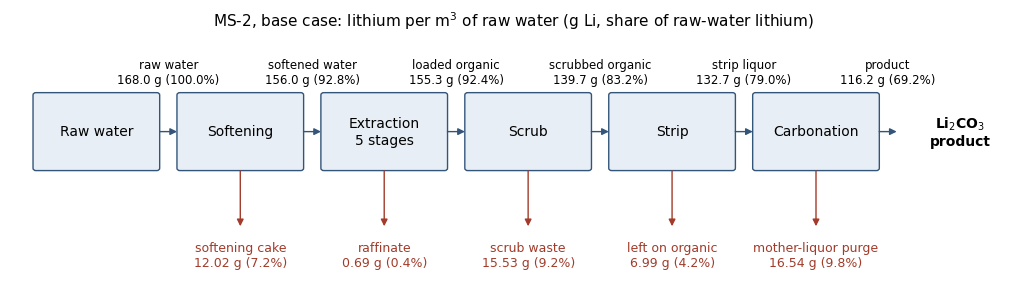

Lithium balance residual (raw water minus product and losses): 6.0e-16 mol per L of raw water


In [25]:
pw.lithium_diagram(result, site)

### 9.4 Stream tables

Every physical stream in mmol per litre (mol per m$^3$) of raw water: aqueous and reagent streams by element or ion,
organic streams by species (`BTA_total` and `TOPO_total` count all HBTA and TOPO).

In [26]:
aqueous_streams, organic_streams = pw.stream_tables(result)
aqueous_streams

,Li,Na,K,Ca,Mg,Sr,Cl,H,OH,C,BTA,water
washed extraction feed,22.5,"5,007",54.6,0.000839,0.0012,0.000158,"4,944",296,,194,,"51,155"
physical raffinate,0.0997,"5,033",54.6,0.000839,0.0012,0.000158,"4,944",296,0.0181,194,3.69,"51,155"
saponification NaOH input,,71.1,,,,,,,71.1,,,
scrub HCl input,,,,,,,102,102,,,,
scrub waste,2.24,40.5,,,,,102,58.8,,,,
gross strip HCl input,,,,,,,254,254,,,,
recovered unused strip HCl,,,,,,,207,207,,,,
strip liquor before neutralization,19.1,4.5,,,,,46.6,23,,,,
regeneration lithium discharge,1.01,,,,,,,,,,,
neutralization NaOH input,,23,,,,,,,23,,,


In [27]:
organic_streams

,hbta,topo,LiA·T complex,NaA·T complex,diluent,BTA_total,TOPO_total,HBTA,TOPO
saponified organic input,30.5,30.5,0,71.1,"4,394",,,,
loaded organic,30.5,34.2,22.4,45,"4,394",,,,
organic loss,,,,,43.9,0.978,1.02,,
regenerated organic,,,,,"4,350",96.9,101,,
organic make-up input,,,,,43.9,,,4.67,1.02


### 9.5 Extraction stage profile

Lithium moves from the water into the organic stage by stage, while the saponified organic gives up its sodium. LiA·T and
NaA·T are the lithium and sodium complexes. Amounts are mmol per litre
of softened water leaving each stage.

In [28]:
pw.stage_table(result)

,lithium-cation,sodium-cation,LiA·T complex,NaA·T complex,hbta,bta-anion
stage,,,,,,
1,10.9,"4,945",22,44.3,30,2.09
2,4.14,"4,952",10.8,57.6,30,2.88
3,1.37,"4,956",4.04,65.2,30,3.34
4,0.408,"4,957",1.27,68.4,30,3.55
5,0.0982,"4,957",0.31,69.6,30,3.64


### 9.6 Operating cost

Each item's cost is read from the costing block (`aggregate_flow_costs`) and divided by the lithium in the product.
HBTA replacement dominates: HBTA dissolves into the raffinate on every pass on top of the 1 % mechanical loss, and is
priced at a screening value of 100 USD/kg. Softening soda ash is second, because MS-2 carries about 240 kg of calcium
and magnesium per kg of lithium.

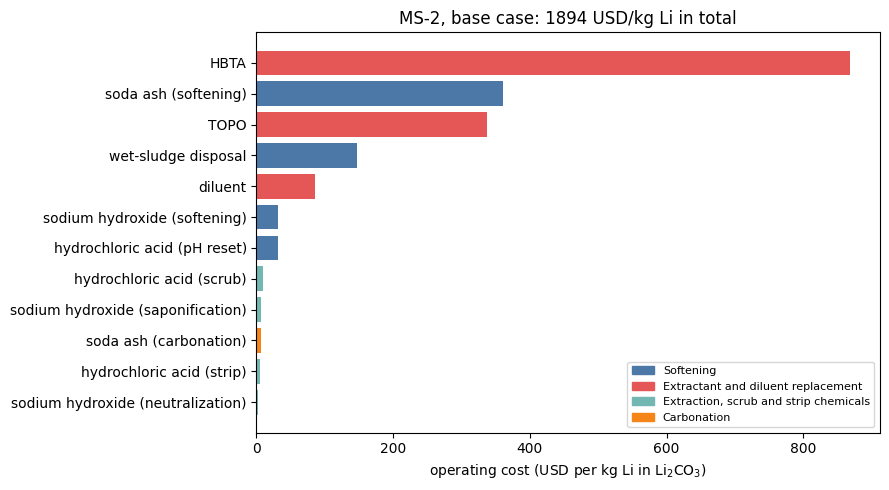

,USD/m3 raw water,USD/kg Li
step,,
Softening,66.4,572
Extractant and diluent replacement,150,"1,293"
"Extraction, scrub and strip chemicals",2.8,24.2
Carbonation,0.7,6.1


In [29]:
costs = pw.costs(m)
pw.plot_costs(costs, site, result["cost_usd_kg_li"])
costs.groupby("step", sort=False)[["USD/m3 raw water", "USD/kg Li"]].sum().round(1)

#### Price sensitivity

The prices are screening values. Scale each group of prices with the sliders to see how the operating cost and the
break-even price move. The flows stay at the solved design, so this is a price sensitivity, not a new optimization:
at other prices the cheapest design could change.

In [30]:
pw.price_sensitivity(m, result)

interactive(children=(FloatSlider(value=1.0, continuous_update=False, description='softening reagents', layout…

## Step 10: Mars Hill with the Lithium_Extraction project's builders

`pw.run_water` solves another water at its own selected design with the Lithium_Extraction project's own flowsheet
builders (`set_c.build_flowsheet`, `optimization.decisions`, `full_process.connect_units`), which write the same units
as Steps 3 to 8. Agreement of both waters with the paper's results, in the reproduction check at the end, checks the
two builds against each other.

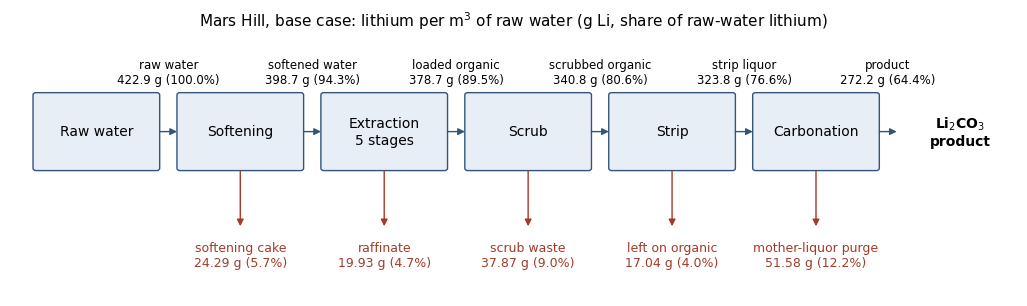

Lithium balance residual (raw water minus product and losses): 5.9e-16 mol per L of raw water


In [31]:
results = {site: result}
mars_hill, results["MarsHill"] = pw.run_water("MarsHill", softened)
pw.lithium_diagram(results["MarsHill"], "MarsHill")

## Step 11: Compare the two waters

### 11.1 Summary

In [32]:
pw.summary(results)

,MS-2,Mars Hill
extraction stages,5,5
HBTA (mol/L organic),0.1,0.112
Li extraction (%),99.6,95
Li recovery to Li2CO3 (%),69.2,64.4
Li2CO3 product (kg per m3 raw),0.619,1.45
operating cost (USD/kg Li),"1,894",733
operating cost (USD/m3 raw water),220,200
break-even price (USD/kg LCE),356,138


### 11.2 Stage profiles

The water enters stage 1 and leaves the last stage as raffinate; the organic flows the other way. Left: lithium left
in the water leaving each stage (log scale). Right: the lithium and sodium complexes in the organic leaving each stage.

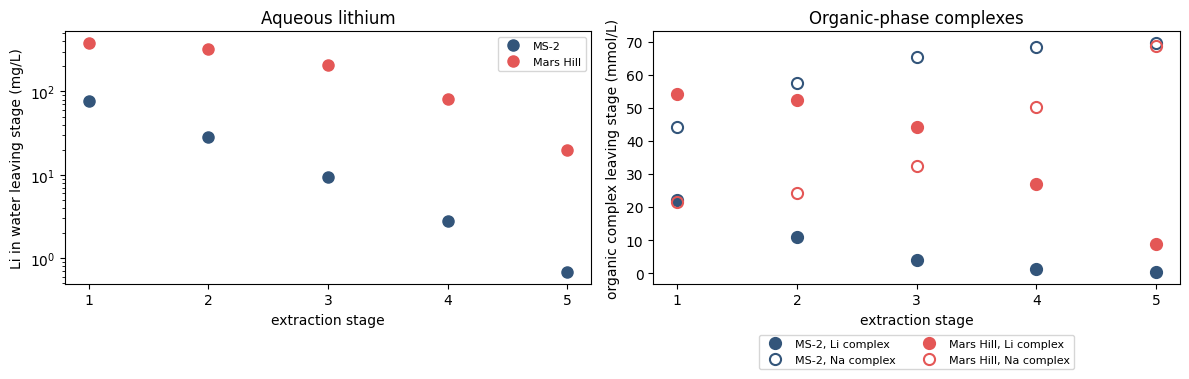

In [33]:
pw.plot_profiles(results)

### 11.3 Break-even lithium carbonate price

Both waters need a price far above the base (17.5 USD/kg LCE) and optimistic (20.9 USD/kg LCE) prices. Capital,
labor and energy, which are excluded, would raise these numbers further. The table gives each break-even price
and how many times the base price it is.

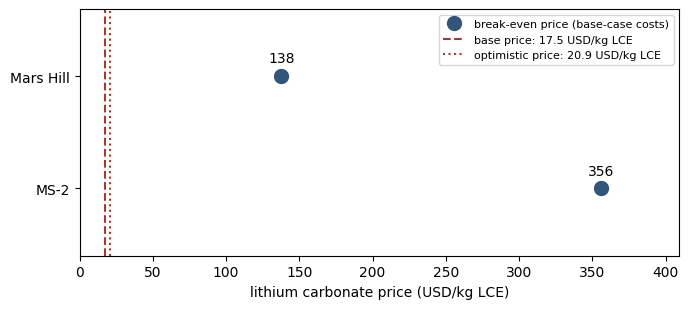

,break-even (USD/kg LCE),times base price
MS-2,356,20.3
Mars Hill,138,7.87


In [34]:
pw.plot_break_even(results)

## Step 12: How the process model is connected

The whole process is one IDAES flowsheet built from standard unit models: PrOMMiS `SolventExtraction` units for the
extraction, scrub, strip and re-saponification, IDAES `Separator`, `Mixer` and `Translator` units for acid recovery,
neutralization, concentration and organic reuse, and the PrOMMiS `Precipitator` with a mixer and splitter for
carbonation. Each row is one unit: its model type and its ports, the points where streams enter and leave.

In [35]:
tools.unit_models(m)

,model class,ports
unit,,
extraction,SolventExtraction,"aqueous_inlet, aqueous_outlet, organic_inlet, ..."
acid_recovery,Separator,"inlet, recovered, liquor"
strip_liquid,Translator,"inlet, outlet"
neutralization,Mixer,"acid, caustic, outlet"
neutral_projection,Translator,"inlet, outlet"
concentration,Separator,"inlet, concentrate, recycle"
regeneration,Translator,"inlet, outlet"
regenerated,Separator,"inlet, organic, lithium_discharge"
organic_loss,Separator,"inlet, organic kept for reuse, loss"


Arcs are the pipes between units: each one makes the stream leaving one port the stream entering the next. The loaded
organic reaches the scrub through the equations of Step 7.1 rather than an Arc, and the prepared organic is compared
with the extraction's organic feed rather than recycled into it (Step 7.3).

In [36]:
tools.arcs(m)

,from,to
arc,,
strip.scrubbed_organic,scrub.unit.organic_outlet,strip.unit.organic_inlet
acid_recovery.feed,strip.unit.aqueous_outlet,acid_recovery.inlet
strip_liquid.feed,acid_recovery.liquor,strip_liquid.inlet
neutralization.feed,strip_liquid.outlet,neutralization.acid
neutral_projection.feed,neutralization.outlet,neutral_projection.inlet
concentration.feed,neutral_projection.outlet,concentration.inlet
regeneration.feed,strip.unit.organic_outlet,regeneration.inlet
regenerated.feed,regeneration.outlet,regenerated.inlet
organic_loss.feed,regenerated.organic,organic_loss.inlet


## Step 13: Explore the options

The process explorer app lets you pick a produced water, a price case, the lithium–sodium exchange fit, the number of
extraction stages, and whether to read the paper's result or solve it again. The same choices are here as widgets.

- **produced water**: the four measured waters, three Smackover samples from Arkansas (MS-2, BR-2, Mars Hill) and the
  Marcellus sample from Westmoreland County, Pennsylvania;
- **price case**: base or optimistic reagent and product prices;
- **Li/Na exchange**: two published data sets give two values of the lithium–sodium exchange constant; the paper's
  results use the single-stage fit, which gives the higher cost, and the cascade fit is the alternative;
- **extraction stages**: 1 to 5;
- **calculation**: *the paper's result* reads it instantly; *solve the design* runs the whole process at the paper's
  design for that choice; *optimize the design* lets IPOPT choose the HBTA concentration that minimizes the operating
  cost per kg of lithium, as the paper's optimization did. A solve uses the same calculation as the app, in a separate
  process, and takes from a few seconds to about five minutes.

Change the widgets, then run the cell below them; every run adds a row to the comparison. Widgets show only in a
running notebook opened as described in "Running this notebook" at the top.

In [37]:
options = pw.Options()
options

Options(children=(Dropdown(description='produced water', layout=Layout(width='620px'), options=(('MS-2', 'MS2'…

Run the current selection:

In [38]:
pw.run_selection(options)

,produced water,prices,Li/Na exchange,stages,calculation,result,HBTA (mol/L),Li extraction (%),Li to Li2CO3 (%),USD/m3 raw water,USD/kg Li,break-even (USD/kg LCE)
0,MS-2,base,single-stage fit,5,the paper's result,optimized,0.1,99.6,69.2,220,"1,894",356


Start the comparison with the selected design of every water at base prices and the single-stage fit, then compare
everything shown so far. Rerun this cell after each new selection to see it beside the others.

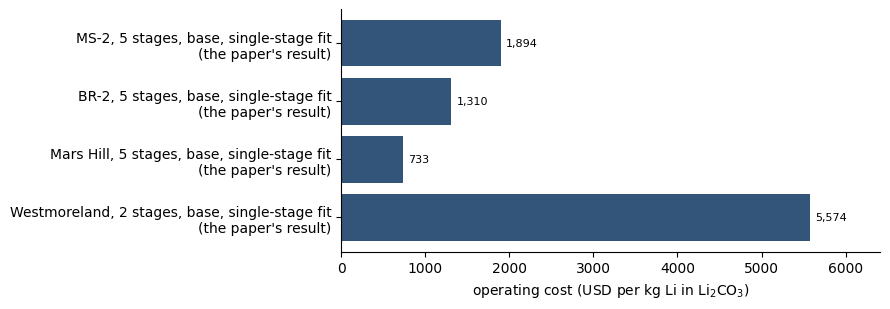

,produced water,prices,Li/Na exchange,stages,calculation,result,HBTA (mol/L),Li extraction (%),Li to Li2CO3 (%),USD/m3 raw water,USD/kg Li,break-even (USD/kg LCE)
0,MS-2,base,single-stage fit,5,the paper's result,optimized,0.1,99.6,69.2,220,"1,894",356
1,BR-2,base,single-stage fit,5,the paper's result,optimized,0.1,99.1,66.4,219,"1,310",246
2,Mars Hill,base,single-stage fit,5,the paper's result,optimized,0.112,95,64.4,200,733,138
3,Westmoreland,base,single-stage fit,2,the paper's result,optimized,0.1,97.4,73.8,481,"5,574","1,047"


In [39]:
pw.add_selected_designs()

At their selected designs, the cost per kg of lithium falls as the lithium in the water rises: Westmoreland (117 mg/L Li)
costs the most and Mars Hill (423 mg/L) the least, with MS-2 (168 mg/L) and BR-2 (252 mg/L) between. Westmoreland
costs the most even though it carries the least calcium and magnesium per kg of lithium.

## The paper's other results

Two parts of the paper are not solved in this notebook; they are read here from the same result tables the manuscript
uses.

**D2EHDTPA/BuPhen.** This route extracts from the raw water without whole-water softening, and ideal cleanup of the
strip liquor is assumed. Its two extractants are not priced, so for each assumed lithium carbonate price the paper gives
the highest BuPhen price at which the process would still cover its operating cost, with D2EHDTPA unpriced.

In [40]:
pw.buphen_results()

Li to Li2CO3 (%)  \
water        price case                     
MS-2         base                    78.1   
             optimistic                83   
BR-2         base                    78.3   
             optimistic              83.2   
Mars Hill    base                    78.4   
             optimistic              83.3   
Westmoreland base                    78.5   
             optimistic              83.3   

                         BuPhen price ceiling at 17.5 USD/kg LCE (USD/kg)  \
water        price case                                                     
MS-2         base                                                    86.6   
             optimistic                                               230   
BR-2         base                                                     154   
             optimistic                                               397   
Mars Hill    base                                                     246   
             optimistic                                               668   
Westmoreland base                                                    46.4   
             optimistic                                               130   

                         BuPhen price ceiling at 20.9 USD/kg LCE (USD/kg)  
water        price case                                                    
MS-2         base                                                     117  
             optimistic                                               301  
BR-2         base                                                     199  
             optimistic                                               504  
Mars Hill    base                                                     309  
             optimistic                                               830  
Westmoreland base                                                    67.3  
             optimistic                                               180

**Primary-calibration HBTA/TOPO best case and hardness target.** The lowest HBTA/TOPO break-even price among the
paper's primary-calibration designs, and how
far the calcium plus magnesium of Mars Hill would have to fall for its optimistic case to break even. That softer water
is a constructed case, the measured analysis with calcium and magnesium scaled down; producing such water is not
priced.

In [41]:
pw.hbta_targets()

Lowest primary-calibration HBTA/TOPO break-even (USD/kg LCE)                           32.9
lowest break-even: water, prices, stages                           Mars Hill, optimistic, 3
Mars Hill (Ca+Mg)/Li, measured (kg/kg)                                                 74.6
Mars Hill (Ca+Mg)/Li to break even at optimistic prices (kg/kg)                23.5 to 23.8
Name: HBTA/TOPO, dtype: object

## What the numbers mean, and their limits

- At base-case prices the MS-2 process recovers about 69 % of the raw water's lithium as lithium carbonate, at an
  operating cost near 1,900 USD/kg Li, so it needs about 356 USD/kg LCE to break even, against 17.5 to 20.9 USD/kg
  LCE. Mars Hill, with more lithium and less hardness per lithium, needs about 138 USD/kg LCE. HBTA replacement and
  softening soda ash are the largest costs.
- These are **model predictions**: ePC-SAFT equilibrium stages with exchange constants fitted to laboratory data on
  other solutions, laboratory scrub and strip fractions transferred to produced water, and measured lithium carbonate
  solubility. Nothing here was measured on these waters; there is no physical validation.
- Softening uses fixed reagent ratios; extractant prices and mechanical loss are screening assumptions, not quotes.
- The operating cost excludes energy, capital and labor, so the break-even prices are lower bounds.
- The agreement in the reproduction check below is **numerical reproduction** of the paper's results, not a check
  against plant data.

**What is read rather than solved.** The paper's optimization over 1 to 5 stages and the HBTA concentration, the other
two waters (BR-2 and Westmoreland), the optimistic prices, the cascade-fit alternative, the D2EHDTPA/BuPhen process and
the plant-costing screen are read from the paper's results, not solved here; the widgets in Step 13 can solve any one
choice again.

## Reproduction check

Every reproduced number is compared with the paper's results: the record of each water's selected design, the
manuscript's summary table and the softening result.

| Quantity | Limit |
|---|---|
| costs and break-even prices | relative $10^{-6}$ (cost items: $10^{-6}$ of the total) |
| extraction and recovery fractions, HBTA loss | absolute $10^{-9}$ |
| stage outlets and physical streams | absolute $10^{-9}$ mol per litre |
| softening result | relative $10^{-9}$, absolute $10^{-12}$ ($10^{-9}$ for the HCl dose and pH) |

The figure puts every comparison on one scale, its difference divided by its limit: a point below the red line is
within its limit, and a difference of $10^{-12}$ of the limit or less (exact agreement included) sits on the bottom
line. The cell stops with an error if any quantity is outside its limit; `checks` holds every line.

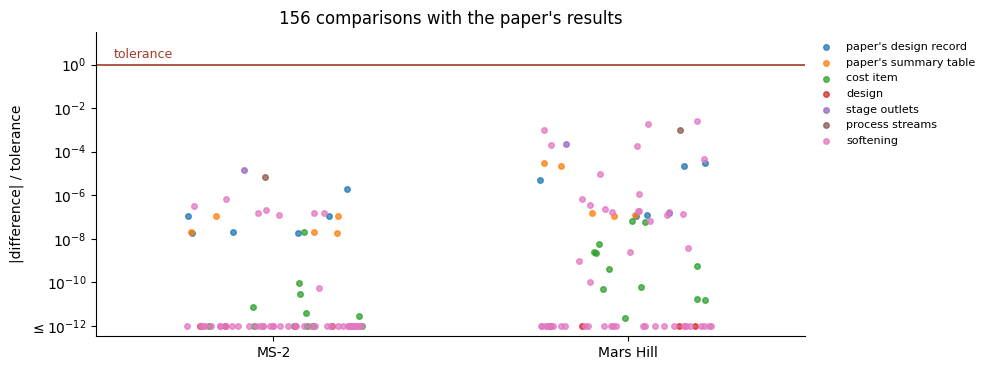

,comparisons,largest difference / tolerance,all within tolerance
MS-2,78,1.4e-05,✓
Mars Hill,78,2.7e-03,✓


In [42]:
summary, checks = pw.check_against_paper(results, softened)
summary